In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pyomo.environ import (
    ConcreteModel,
    Var,
    Constraint,
    Expression,
    Param,
    Objective,
    SolverFactory,
    value,
    assert_optimal_termination,
    units as pyunits,
)
from idaes.core.util.model_statistics import degrees_of_freedom

from watertap.core.util.model_diagnostics.infeasible import (
    print_infeasible_constraints,
    print_variables_close_to_bounds,
    print_close_to_bounds,
)

solver = SolverFactory("ipopt")

In [3]:
## Inlet Conditions

# Flow rate in L/s
initial_flow = {"feed": 100, "brine": 50, "product": 50}

# Concentration in g/L
initial_concentration = {"feed": 35, "brine": 70, "product": 1}

# Maximum product concentration in g/L
max_product_concentration = 0.5

# Names of streams for indexing Vars
streams = ["feed", "brine", "product"]

In [4]:
# Create model

m = ConcreteModel()

## Define model parameters
m.temperature = Param(
    initialize=298.15,
    mutable=True,
    units=pyunits.kelvin,
    doc="Feed temperature",
)
m.pressure_atm = Param(
    initialize=1.0,
    mutable=True,
    units=pyunits.bar,
    doc="Atmospheric pressure",
)
m.density_freshwater = Param(
    initialize=1000,
    mutable=True,
    units=pyunits.kg / pyunits.m**3,
    doc="Density of freshwater",
)
m.density_saltwater = Param(
    initialize=1023,
    mutable=True,
    units=pyunits.kg / pyunits.m**3,
    doc="Density of saltwater",
)
m.mw_NaCl = Param(
    initialize=58.44,
    mutable=True,
    units=pyunits.gram / pyunits.mole,
    doc="Molecular weight of NaCl",
)
m.vant_hoff_factor = Param(
    initialize=0.93,
    mutable=True,
    units=pyunits.dimensionless,
    doc="Van't Hoff factor for NaCl",
)
m.osmotic_coefficient = Param(
    initialize=2,
    mutable=True,
    units=pyunits.dimensionless,
    doc="Osmotic coefficient for NaCl",
)
m.univ_gas_constant = Param(
    initialize=0.08314,
    mutable=True,
    units=(pyunits.bars * pyunits.liter) / (pyunits.mole * pyunits.kelvin),
    doc="Universal gas constant",
)
m.channel_height = Param(
    initialize=1,
    mutable=True,
    units=pyunits.mm,
    doc="Channel height of the membrane",
)
################################################################################
## Define state variables
m.flow = Var(
    streams,
    initialize=initial_flow,
    units=pyunits.liters / pyunits.s,
    bounds=(1, None),
    doc="Flow rate of different streams",
)

m.concentration_mass = Var(
    streams,
    initialize=initial_concentration,
    units=pyunits.grams / pyunits.liter,
    bounds=(0.01, 100),
    doc="Concentration of NaCl in different streams",
)


## Properties
# Molar concetration for osmotic pressure calculation
def rule_concentration_mol(m, s):
    return pyunits.convert(
        m.concentration_mass[s] / m.mw_NaCl, to_units=pyunits.mole / pyunits.liter
    )


m.concentration_mol = Expression(
    streams,
    rule=rule_concentration_mol,
)


# Osmotic pressure
m.osmotic_pressure = Var(
    streams,
    units=pyunits.bar,
    bounds=(0.001, 85),
    doc="Osmotic pressure of different streams",
)


def rule_osmotic_pressure(m, s):
    return m.osmotic_pressure[s] == pyunits.convert(
        m.osmotic_coefficient
        * m.vant_hoff_factor
        * m.concentration_mol[s]
        * m.univ_gas_constant
        * m.temperature,
        to_units=pyunits.bar,
    )


m.osmotic_pressure_constraint = Constraint(streams, rule=rule_osmotic_pressure)
# Average inlet osmotic pressure
m.osmotic_pressure_avg = Expression(
    expr=(m.osmotic_pressure["feed"] + m.osmotic_pressure["brine"]) / 2
)
# Average inlet concentration
m.concentration_mass_avg = Expression(
    expr=(m.concentration_mass["feed"] + m.concentration_mass["brine"]) / 2
)

#### Given material ends here
################################################################################
################################################################################
################################################################################
#### TIY Starts Below


#### Mass Balance
def rule_mass_balance_salt(m):
    return (
        m.flow["feed"] * m.concentration_mass["feed"]
        == m.flow["brine"] * m.concentration_mass["brine"]
        + m.flow["product"] * m.concentration_mass["product"]
    )


m.mass_balance_salt_constraint = Constraint(rule=rule_mass_balance_salt)


# def rule_mass_balance_water(m):
#     return (
#         m.flow["feed"] * m.density_saltwater
#         == m.flow["brine"] * m.density_saltwater
#         + m.flow["product"] * m.density_freshwater
#     )


# m.mass_balance_water_constraint = Constraint(rule=rule_mass_balance_water)


### NOTE: This assumes the same density for all streams
def rule_flow_balance(m):
    return m.flow["feed"] == m.flow["brine"] + m.flow["product"]


m.flow_balance_constraint = Constraint(rule=rule_flow_balance)


LMH = pyunits.liter / pyunits.m**2 / pyunits.hour

### Design Variables
m.A_coeff = Var(
    initialize=1.5,
    units=LMH / pyunits.bar,
    bounds=(1, 3),
    doc="A coefficient for the system",
)
m.B_coeff = Var(
    initialize=0.1,
    units=LMH,
    bounds=(0, 1),
    doc="B coefficient for the system",
)

### Decision Variables
m.area = Var(
    initialize=25,
    units=pyunits.m**2,
    bounds=(1, None),
    doc="Total membrane area",
)

# We assume this is deltaP = (P_feed + P_brine) / 2
m.pump_pressure = Var(
    initialize=45,
    units=pyunits.bar,
    bounds=(40, 85),
    doc="Operating pressure of the pump",
)

m.pump_power = Var(
    initialize=1.0,
    units=pyunits.kW,
    bounds=(0, None),
    doc="Pump power of the system",
)


def rule_pump_power(m):
    return m.pump_power == pyunits.convert(
        (m.pump_pressure - m.pressure_atm) * m.flow["feed"],
        to_units=pyunits.kW,
    )


m.pump_power_constraint = Constraint(rule=rule_pump_power)


# Recovery
m.recovery = Var(
    initialize=0.5,
    units=pyunits.dimensionless,
    bounds=(0, 1),
    doc="Recovery of the system",
)


def rule_recovery(m):
    return m.recovery == pyunits.convert(
        m.flow["product"] / m.flow["feed"],
        to_units=pyunits.dimensionless,
    )


m.recovery_constraint = Constraint(rule=rule_recovery)


# Water Flux
m.flux_water = Var(
    initialize=15,
    units=pyunits.liters / pyunits.m**2 / pyunits.hour,
    bounds=(15, 30),
    doc="Water flux of the system",
)


def rule_flux_water(m):
    return m.flux_water == pyunits.convert(
        m.flow["product"] / m.area,
        to_units=pyunits.liters / pyunits.m**2 / pyunits.hour,
    )


m.flux_constraint = Constraint(rule=rule_flux_water)


# Salt Flux
m.flux_salt = Var(
    initialize=15,
    units=pyunits.gram / pyunits.m**2 / pyunits.hour,
    bounds=(0, 100),
    doc="Salt flux of the system",
)


def rule_salt_flux(m):
    return m.flux_salt == pyunits.convert(
        m.concentration_mass["product"] * m.flux_water,
        to_units=pyunits.gram / pyunits.m**2 / pyunits.hour,
    )


m.salt_flux_constraint = Constraint(rule=rule_salt_flux)


# Solution-Diffusion Equations
def rule_solution_diffusion_water(m):
    return m.flux_water == pyunits.convert(
        m.A_coeff * (m.pump_pressure - m.osmotic_pressure_avg),
        to_units=pyunits.liters / pyunits.m**2 / pyunits.hour,
    )


m.solution_diffusion_water_constraint = Constraint(rule=rule_solution_diffusion_water)


# NOTE: We are ignoring permeate concentration
def rule_solution_diffusion_salt(m):
    return m.flux_salt == pyunits.convert(
        m.B_coeff * m.concentration_mass_avg,
        to_units=pyunits.gram / pyunits.m**2 / pyunits.hour,
    )


m.solution_diffusion_salt_constraint = Constraint(rule=rule_solution_diffusion_salt)

# Product concentration upper bound
m.product_concentration_ub = Constraint(
    expr=m.concentration_mass["product"] <= max_product_concentration
)

m.SEC = Expression(
    expr=pyunits.convert(
        m.pump_power / m.flow["product"],
        to_units=pyunits.kWh / pyunits.m**3,
    )
)
m.obj = Objective(expr=m.SEC)


# Fix variables
m.A_coeff.fix()
m.B_coeff.fix()
m.concentration_mass["feed"].fix(35)
m.flow["feed"].fix(100)
m.recovery.fix(0.5)

# 1 DOF is pressure or membrane area
print(f"dof = {degrees_of_freedom(m)}")

results = solver.solve(m, tee=False)
assert_optimal_termination(results)
print(f"termination = {results.solver.termination_condition}")
# print_infeasible_constraints(m)
# print_close_to_bounds(m)

dof = 1
termination = optimal


In [5]:
recoverys = np.linspace(0.25, 0.65, 21)
SECs = list()
areas = list()
for rec in recoverys:
    m.recovery.fix(rec)
    results = solver.solve(m, tee=False)
    assert_optimal_termination(results)
    print(f"\nRecovery = {rec*100:.1f}%")
    print(f"Termination = {results.solver.termination_condition}")
    print(f"Pump power = {value(m.pump_power):.1f} kW")
    print(f"Pump pressure = {value(m.pump_pressure):.1f} bar")
    print(
        f"Product concentration = {value(m.concentration_mass['product']*1e3):.1f} ppm"
    )
    print(f"Flux water = {value(m.flux_water):.1f} LMH")
    print(f"Area = {value(m.area):.0f} m2")
    print(f"Specific energy consumption = {value(m.SEC):.2f} kWh/m3")
    SECs.append(value(m.SEC))
    areas.append(value(m.area))


Recovery = 25.0%
Termination = optimal
Pump power = 411.8 kW
Pump pressure = 42.2 bar
Product concentration = 271.9 ppm
Flux water = 15.0 LMH
Area = 6000 m2
Specific energy consumption = 4.58 kWh/m3

Recovery = 27.0%
Termination = optimal
Pump power = 416.8 kW
Pump pressure = 42.7 bar
Product concentration = 276.1 ppm
Flux water = 15.0 LMH
Area = 6480 m2
Specific energy consumption = 4.29 kWh/m3

Recovery = 29.0%
Termination = optimal
Pump power = 422.1 kW
Pump pressure = 43.2 bar
Product concentration = 280.6 ppm
Flux water = 15.0 LMH
Area = 6960 m2
Specific energy consumption = 4.04 kWh/m3

Recovery = 31.0%
Termination = optimal
Pump power = 427.7 kW
Pump pressure = 43.8 bar
Product concentration = 285.3 ppm
Flux water = 15.0 LMH
Area = 7440 m2
Specific energy consumption = 3.83 kWh/m3

Recovery = 33.0%
Termination = optimal
Pump power = 433.6 kW
Pump pressure = 44.4 bar
Product concentration = 290.3 ppm
Flux water = 15.0 LMH
Area = 7920 m2
Specific energy consumption = 3.65 kWh/m3


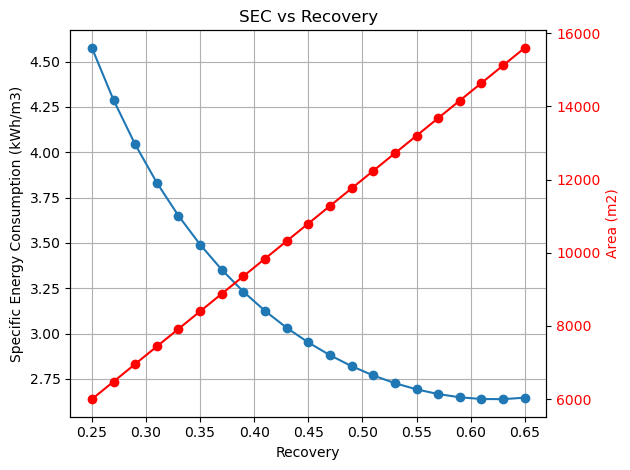

In [6]:
fig, ax = plt.subplots()
ax2 = ax.twinx()
ax.plot(recoverys, SECs, marker="o")
ax.set_xlabel("Recovery")
ax.set_ylabel("Specific Energy Consumption (kWh/m3)")
ax.set_title("SEC vs Recovery")
ax.grid(True)
ax2.plot(recoverys, areas, marker="o", color="r")
ax2.set_ylabel("Area (m2)", color="r")
ax2.tick_params(axis="y", labelcolor="r")
fig.tight_layout()